# FALCON Benchmark H1 - Source Data Exploration (DANDI 000954)

**Human 7-DoF Reach and Grasp Motor BCI.** Single human iBCI participant
(`sub-HumanPitt`), two 96-channel Utah arrays in hand-knob motor cortex.

This is a **Tier-1** dataset: NWB is read **in place by streaming** over the
network (`remfile` + `h5py` + `pynwb`) -- no bulk download, no caching of whole
files. The cells below stream one or two small assets and inspect structure,
neural data, 7-DoF kinematics, FALCON splits and eval masks.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from neuralshed.datasets import nwb
from neuralshed.datasets.fan_h1 import utils

print("bin size:", utils.BIN_SIZE_S, "s ->", utils.BIN_RATE_HZ, "Hz")
print("arrays:", utils.ARRAYS, "| area:", utils.BRAIN_AREA)
print("DoF labels:", utils.DOF_LABELS)

bin size: 0.02 s -> 50.0 Hz
arrays: 2 x 96-channel Utah arrays | area: hand-knob motor cortex (precentral gyrus)
DoF labels: ('tx', 'ty', 'tz', 'rx', 'g1', 'g2', 'g3')


## Assets and FALCON splits

In [2]:
assets = utils.list_assets()
df = pd.DataFrame(assets)
df["size_MB"] = (df["size"] / 1e6).round(2)
print("total assets:", len(df))
display(df.groupby("split").agg(n=("path", "size"),
                                MB=("size_MB", "sum")).round(1))
display(df[["path", "split", "size_MB"]].head(8))

total assets: 40


,n,MB
split,,
held-in-calib,13,69.8
held-in-minival,13,13.4
held-out-calib,14,19.1


,path,split,size_MB
0,sub-HumanPitt-held-in-calib/sub-HumanPitt-held...,held-in-calib,5.16
1,sub-HumanPitt-held-in-calib/sub-HumanPitt-held...,held-in-calib,3.09
2,sub-HumanPitt-held-in-calib/sub-HumanPitt-held...,held-in-calib,5.80
3,sub-HumanPitt-held-in-calib/sub-HumanPitt-held...,held-in-calib,3.31
4,sub-HumanPitt-held-in-calib/sub-HumanPitt-held...,held-in-calib,3.15
5,sub-HumanPitt-held-in-calib/sub-HumanPitt-held...,held-in-calib,5.85
6,sub-HumanPitt-held-in-calib/sub-HumanPitt-held...,held-in-calib,5.57
7,sub-HumanPitt-held-in-calib/sub-HumanPitt-held...,held-in-calib,5.94


## Stream one NWB file and inspect structure

We pick the smallest held-in-minival asset to keep the demo light. `nwb.open_nwb` (fed by `nwb.resolve_source(...)`) streams by default and closes all handles on exit.

In [3]:
sample = min(assets, key=lambda a: a["size"])
print("streaming:", sample["path"], f"({sample['size']/1e6:.1f} MB)")

with nwb.open_nwb(nwb.resolve_source(sample["asset_id"], utils.DANDISET_ID, utils.VERSION)) as nwbfile:
    print("session_description:", nwbfile.session_description)
    print("identifier:", nwbfile.identifier)
    print("session_start_time:", nwbfile.session_start_time)
    print("lab:", nwbfile.lab, "| institution:", nwbfile.institution)
    print("subject:", nwbfile.subject.subject_id, "| species:", nwbfile.subject.species,
          "| age:", nwbfile.subject.age)
    print("\nacquisition:", list(nwbfile.acquisition.keys()))
    for k, v in nwbfile.acquisition.items():
        print("  ", k, type(v).__name__, getattr(v.data, "shape", None),
              "unit:", getattr(v, "unit", None))
    print("\nunits table: n_units =", len(nwbfile.units.id),
          "| columns:", nwbfile.units.colnames)
    print("intervals:", list(nwbfile.intervals.keys()))

streaming: sub-HumanPitt-held-in-minival/sub-HumanPitt-held-in-minival_ses-19250113T121303.nwb (0.9 MB)


session_description: FALCON H1. Open loop 7DoF calibration.
identifier: HumanPitt-held_in-minival_01-13-12:13_set2
session_start_time: 1925-01-13 12:13:03-05:00
lab: Rehab Neural Engineering Labs | institution: University of Pittsburgh
subject: HumanPitt-held_in-minival | species: Homo sapiens | age: P22Y/P70Y

acquisition: ['OpenLoopKinematics', 'OpenLoopKinematicsVelocity', 'TrialNum', 'eval_mask']
   OpenLoopKinematics TimeSeries (1536, 7) unit: arbitrary
   OpenLoopKinematicsVelocity TimeSeries (1536, 7) unit: arbitrary
   TrialNum TimeSeries (1536,) unit: arbitrary
   eval_mask TimeSeries (1536,) unit: bool

units table: n_units = 176 | columns: ('spike_times',)
intervals: ['epochs']


In [4]:
nwbfile = nwb.load_nwb(nwb.resolve_source(sample["asset_id"], utils.DANDISET_ID, utils.VERSION))
nwbfile

Data type,float64
Shape,"(1536, 7)"
Array size,84.00 KiB
Chunk shape,None
Compression,None
Compression opts,None
Uncompressed size (bytes),86016
Compressed size (bytes),86016
Compression ratio,1.0
Data type,float32
Shape,"(1536, 7)"


In [5]:
nwbfile.epochs.to_dataframe()#["tags"]

,start_time,stop_time,tags,timeseries
id,,,,
0,0.00,0.04,[Intertrial],"[(0, 0, OpenLoopKinematics pynwb.base.TimeSeri..."
1,0.04,1.08,[Presentation],"[(0, 0, OpenLoopKinematics pynwb.base.TimeSeri..."
2,1.08,2.70,[Reach],"[(0, 0, OpenLoopKinematics pynwb.base.TimeSeri..."
3,2.70,4.22,[Presentation2],"[(0, 0, OpenLoopKinematics pynwb.base.TimeSeri..."
4,4.22,5.44,[Orient],"[(0, 0, OpenLoopKinematics pynwb.base.TimeSeri..."
5,5.44,5.66,[SnapTo],"[(0, 0, OpenLoopKinematics pynwb.base.TimeSeri..."
6,5.66,7.20,[Presentation3],"[(0, 0, OpenLoopKinematics pynwb.base.TimeSeri..."
7,7.20,7.82,[Shape],"[(0, 0, OpenLoopKinematics pynwb.base.TimeSeri..."
8,7.82,9.36,[Presentation4],"[(0, 0, OpenLoopKinematics pynwb.base.TimeSeri..."


## Neural data (spike times) + 7-DoF kinematics, aligned in time

In [6]:
with nwb.open_nwb(nwb.resolve_source(sample["asset_id"], utils.DANDISET_ID, utils.VERSION)) as nwbfile:
    spikes = utils.get_spike_times(nwbfile)        # list of arrays (s)
    counts = utils.bin_spikes(nwbfile)             # (n_bins, n_units)
    kin = utils.get_kinematics(nwbfile)            # (n_bins, 7)
    t = utils.bin_centers(nwbfile)                 # (n_bins,)
    mask = utils.get_eval_mask(nwbfile)
    trials = utils.get_trials(nwbfile)

print("binned spikes:", counts.shape, "| kinematics:", kin.shape)
print("n trials (epochs):", len(trials))
print("mean firing rate (Hz):",
      round(float(counts.mean() / utils.BIN_SIZE_S), 2))

binned spikes: (1536, 176) | kinematics: (1536, 7)
n trials (epochs): 29
mean firing rate (Hz): 13.11


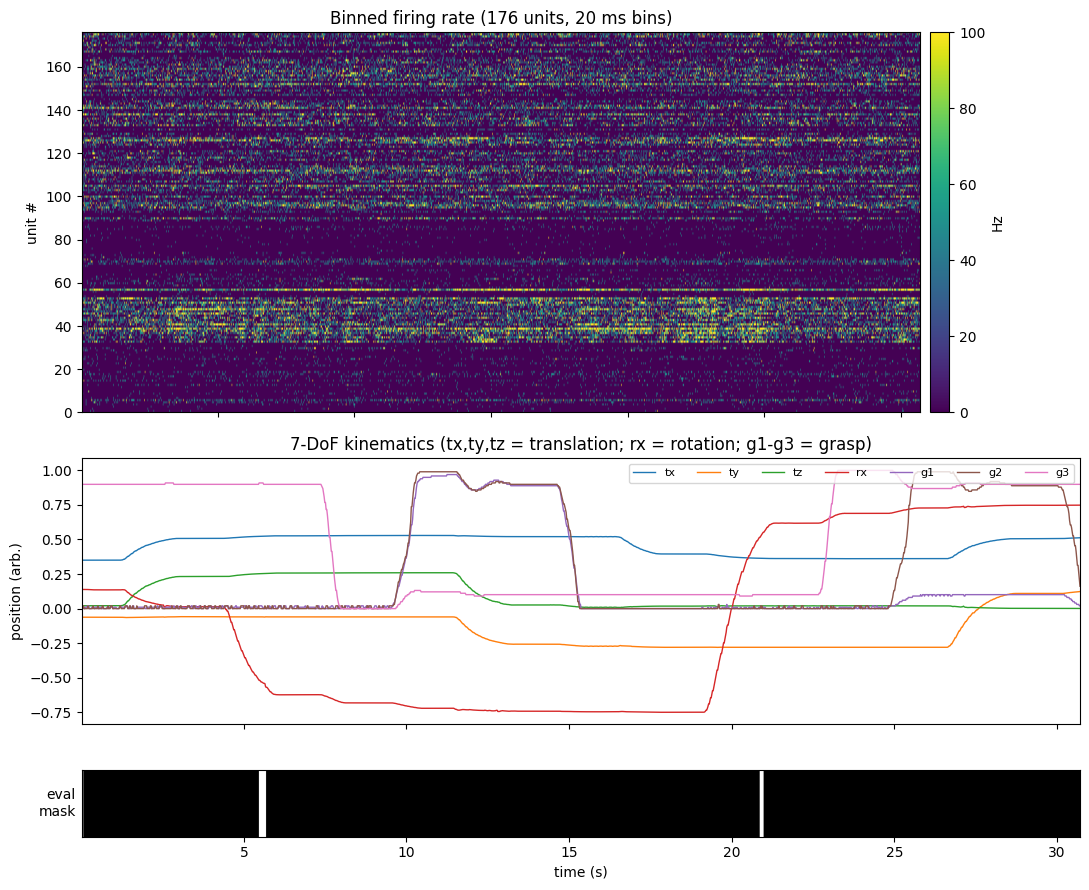

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1.4, 0.35]})

# (1) Binned firing-rate heatmap
rate = counts.T / utils.BIN_SIZE_S  # (n_units, n_bins) in Hz
im = axes[0].imshow(rate, aspect="auto", origin="lower", cmap="viridis",
                    extent=[t[0], t[-1], 0, rate.shape[0]],
                    vmax=np.percentile(rate, 99))
axes[0].set_ylabel("unit #")
axes[0].set_title(f"Binned firing rate ({rate.shape[0]} units, "
                  f"{int(utils.BIN_SIZE_S*1000)} ms bins)")
fig.colorbar(im, ax=axes[0], label="Hz", pad=0.01)

# (2) 7-DoF kinematics
for d in range(utils.N_DOF):
    axes[1].plot(t, kin[:, d], lw=1, label=utils.DOF_LABELS[d])
axes[1].set_ylabel("position (arb.)")
axes[1].set_title("7-DoF kinematics (tx,ty,tz = translation; rx = rotation; "
                  "g1-g3 = grasp)")
axes[1].legend(ncol=7, fontsize=8, loc="upper right")

# (3) FALCON eval mask
axes[2].imshow(mask[None, :], aspect="auto", cmap="Greys",
               extent=[t[0], t[-1], 0, 1])
axes[2].set_yticks([])
axes[2].set_ylabel("eval\nmask", rotation=0, ha="right", va="center")
axes[2].set_xlabel("time (s)")
fig.tight_layout()
plt.show()

## Behavioral data (7-DoF kinematics)

The decoding target is two acquisition `TimeSeries`, both `(n_bins, 7)` on the
20 ms grid:

- **`OpenLoopKinematics`** — 7-DoF *position* (`float64`),
- **`OpenLoopKinematicsVelocity`** — its *velocity* (`float32`).

The 7 DoF (`tx, ty, tz, rx, g1, g2, g3`) are 3 translation, 1 rotation and 3
grasp dimensions, listed in each series' `.description`. As noted above, the
`TimeSeries.rate` field stores `0.02` — the **bin period (s)**, not a sample
rate in Hz.

In [8]:
with nwb.open_nwb(nwb.resolve_source(sample["asset_id"], utils.DANDISET_ID, utils.VERSION)) as nwbfile:
    pos = utils.get_kinematics(nwbfile)                 # (n_bins, 7) position
    vel = utils.get_kinematics(nwbfile, velocity=True)  # (n_bins, 7) velocity
    t = utils.bin_centers(nwbfile)                      # (n_bins,) bin-center times (s)
    trial_num = utils.get_trial_num(nwbfile)            # (n_bins,) per-bin trial index
    info = [(k,
             nwbfile.acquisition[k].data.shape,
             str(nwbfile.acquisition[k].data.dtype),
             nwbfile.acquisition[k].unit,
             nwbfile.acquisition[k].rate,
             nwbfile.acquisition[k].description)
            for k in ("OpenLoopKinematics", "OpenLoopKinematicsVelocity")]

for name, shape, dt, unit, rate, desc in info:
    print(f"{name:28s} shape={shape} dtype={dt} unit={unit!r} "
          f"rate(field)={rate}  '{desc}'")
print(f"\nDoF labels: {utils.DOF_LABELS}")
print(f"NOTE rate field {info[0][4]} is the 20 ms *bin period* (s), not Hz "
      f"-> {utils.BIN_RATE_HZ} Hz")

display(pd.DataFrame({
    "DoF": utils.DOF_LABELS,
    "pos_min": pos.min(0).round(2), "pos_max": pos.max(0).round(2),
    "vel_min": vel.min(0).round(3), "vel_max": vel.max(0).round(3),
}))

OpenLoopKinematics           shape=(1536, 7) dtype=float64 unit='arbitrary' rate(field)=0.02  'tx,ty,tz,rx,g1,g2,g3'
OpenLoopKinematicsVelocity   shape=(1536, 7) dtype=float32 unit='arbitrary' rate(field)=0.02  'tx,ty,tz,rx,g1,g2,g3'

DoF labels: ('tx', 'ty', 'tz', 'rx', 'g1', 'g2', 'g3')
NOTE rate field 0.02 is the 20 ms *bin period* (s), not Hz -> 50.0 Hz


,DoF,pos_min,pos_max,vel_min,vel_max
0,tx,0.35,0.53,-0.003,0.003
1,ty,-0.28,0.12,-0.004,0.007
2,tz,0.00,0.26,-0.005,0.005
3,rx,-0.75,0.75,-0.013,0.021
4,g1,0.00,0.97,-0.028,0.029
5,g2,0.00,0.99,-0.033,0.033
6,g3,0.00,1.00,-0.036,0.038


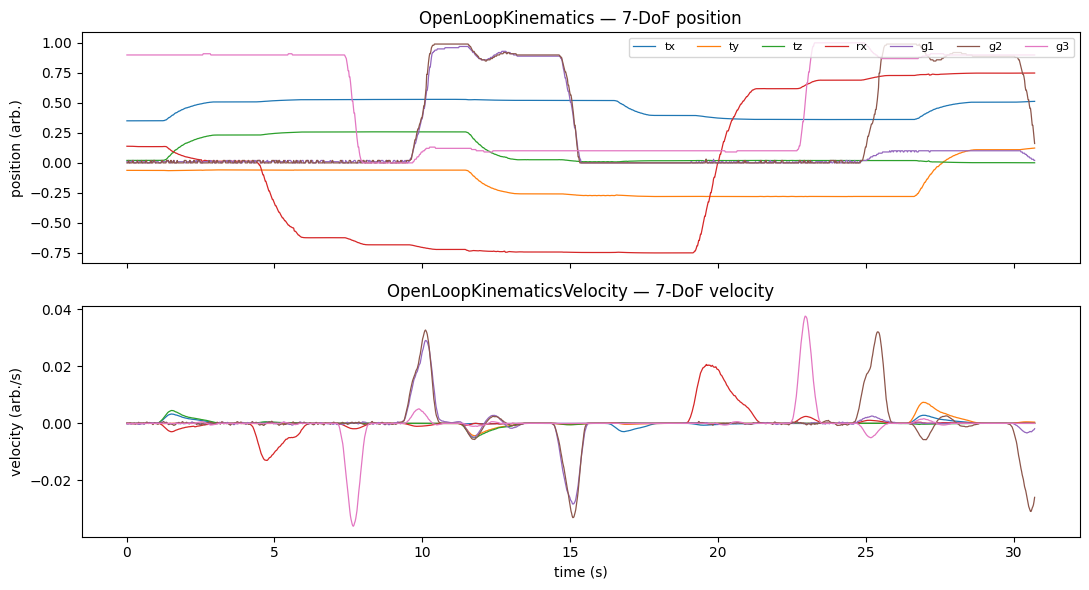

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for d in range(utils.N_DOF):
    axes[0].plot(t, pos[:, d], lw=0.9, label=utils.DOF_LABELS[d])
    axes[1].plot(t, vel[:, d], lw=0.9, label=utils.DOF_LABELS[d])
axes[0].set_title("OpenLoopKinematics — 7-DoF position")
axes[0].set_ylabel("position (arb.)")
axes[0].legend(ncol=7, fontsize=8, loc="upper right")
axes[1].set_title("OpenLoopKinematicsVelocity — 7-DoF velocity")
axes[1].set_ylabel("velocity (arb./s)")
axes[1].set_xlabel("time (s)")
fig.tight_layout()
plt.show()

## Time alignment (spikes, epochs, kinematics)

The three streams the `Study` consumes must share one clock before binning:

- **spike times** — `units.spike_times` (seconds),
- **epochs** — `intervals/epochs` `start_time`/`stop_time` (seconds),
- **behavioral series** — `OpenLoopKinematics` etc., a regular grid at
  `starting_time = 0` with a 20 ms step.

The cell below confirms there is **no per-stream offset**: every acquisition
series shares the same length and `starting_time`; the epochs tile that window
contiguously (no gaps) and within the kinematics span; and the spike times fall
within the same window. So binning spikes on the kinematics grid needs no
realignment. (Whether the epoch *boundaries* land exactly on bin edges varies by
session — see the cross-split table below.)

In [10]:
SERIES = ["OpenLoopKinematics", "OpenLoopKinematicsVelocity", "TrialNum", "eval_mask"]
with nwb.open_nwb(nwb.resolve_source(sample["asset_id"], utils.DANDISET_ID, utils.VERSION)) as nwbfile:
    spikes = utils.get_spike_times(nwbfile)
    trials = utils.get_trials(nwbfile)
    grid = {k: (nwbfile.acquisition[k].data.shape[0],
                nwbfile.acquisition[k].starting_time or 0.0,
                nwbfile.acquisition[k].rate) for k in SERIES}

n_bins, t0, _ = grid["OpenLoopKinematics"]
kin_start, kin_stop = t0, t0 + n_bins * utils.BIN_SIZE_S   # [start, exclusive end)
spk_min = min(s.min() for s in spikes if s.size)
spk_max = max(s.max() for s in spikes if s.size)
tol = utils.BIN_SIZE_S  # one-bin tolerance

print("acquisition timebase (n_bins, starting_time, rate field):")
for k, (n, st, r) in grid.items():
    print(f"  {k:28s} n_bins={n} starting_time={st} rate={r}")
print()
print(f"kinematics span : [{kin_start:.3f}, {kin_stop:.3f}) s  ({n_bins} bins)")
print(f"epochs          : [{trials.start_time.min():.3f}, {trials.stop_time.max():.3f}] s  ({len(trials)} trials)")
print(f"spike times     : [{spk_min:.4f}, {spk_max:.3f}] s  ({len(spikes)} units)")
print()
same_len = len({n for n, _, _ in grid.values()}) == 1
same_t0 = len({st for _, st, _ in grid.values()}) == 1
print("all acquisition series share length & starting_time:", same_len and same_t0)
print("epochs within kinematics span                      :",
      bool(trials.start_time.min() >= kin_start - tol
           and trials.stop_time.max() <= kin_stop + tol))
print("spike times within kinematics span                 :",
      bool(spk_min >= kin_start - tol and spk_max <= kin_stop + tol))

acquisition timebase (n_bins, starting_time, rate field):
  OpenLoopKinematics           n_bins=1536 starting_time=0.0 rate=0.02
  OpenLoopKinematicsVelocity   n_bins=1536 starting_time=0.0 rate=0.02
  TrialNum                     n_bins=1536 starting_time=0.0 rate=0.02
  eval_mask                    n_bins=1536 starting_time=0.0 rate=0.02

kinematics span : [0.000, 30.720) s  (1536 bins)
epochs          : [0.000, 30.700] s  (29 trials)
spike times     : [0.0079, 30.700] s  (176 units)

all acquisition series share length & starting_time: True
epochs within kinematics span                      : True
spike times within kinematics span                 : True


### The same checks for every session

These invariants are structural, so they should hold for every released session —
not just the samples above. The cell below streams **all 40 assets** and runs the
same checks, reading only each unit's first/last spike time (spikes are sorted
within a unit) so the sweep stays light. `aligned` ANDs the realignment-free
invariants: shared bin grid, epochs contiguous and within span, and spikes within
span.

In [11]:
def _spike_extent(nwbfile):
    ends = np.asarray(nwbfile.units.spike_times_index.data[:]).astype(np.int64)
    starts = np.concatenate([[0], ends[:-1]])
    valid = (ends - starts) > 0
    data = nwbfile.units.spike_times.data
    return (float(np.asarray(data[np.unique(starts[valid])]).min()),
            float(np.asarray(data[np.unique(ends[valid] - 1)]).max()))

def _alignment_row(asset):
    with nwb.open_nwb(nwb.resolve_source(asset["asset_id"], utils.DANDISET_ID, utils.VERSION)) as nwbfile:
        grid = {k: (nwbfile.acquisition[k].data.shape[0],
                    nwbfile.acquisition[k].starting_time or 0.0) for k in SERIES}
        n_units = len(nwbfile.units.id)
        tr = utils.get_trials(nwbfile)
        spk_min, spk_max = _spike_extent(nwbfile)
    n_bins, t0 = grid["OpenLoopKinematics"]
    kin_stop = t0 + n_bins * utils.BIN_SIZE_S
    tol = utils.BIN_SIZE_S
    gaps = tr.start_time.values[1:] - tr.stop_time.values[:-1]
    same_grid = (len({n for n, _ in grid.values()}) == 1
                 and len({st for _, st in grid.values()}) == 1)
    aligned = bool(
        same_grid
        and tr.start_time.min() >= t0 - tol and tr.stop_time.max() <= kin_stop + tol
        and spk_min >= t0 - tol and spk_max <= kin_stop + tol
        and np.abs(gaps).max() < tol
    )
    fn = asset["path"].split("/")[-1]
    return {
        "split": asset["split"],
        "session": fn.split("_")[-1].replace(".nwb", "") if "_" in fn else fn,
        "n_bins": n_bins, "n_trials": len(tr), "n_units": n_units,
        "kin_span_s": round(kin_stop - t0, 2),
        "epochs_s": f"[{tr.start_time.min():.2f}, {tr.stop_time.max():.2f}]",
        "spikes_s": f"[{spk_min:.2f}, {spk_max:.2f}]",
        "aligned": aligned,
    }

rows = [_alignment_row(a) for a in sorted(assets, key=lambda a: (a["split"], a["path"]))]
tbl = pd.DataFrame(rows).set_index(["split", "session"])
display(tbl)
print(f"{len(rows)} sessions | all aligned: {all(r['aligned'] for r in rows)}")

n_bins  n_trials  n_units  kin_span_s  \
split           session                                                      
held-in-calib   ses-19250101T111740   10819       187      176      216.38   
                ses-19250101T112404    6456       115      176      129.12   
                ses-19250108T110520   12233       218      176      244.66   
                ses-19250108T111022    6786       117      176      135.72   
                ses-19250108T111455    6505       116      176      130.10   
                ses-19250113T120811   11646       214      176      232.92   
                ses-19250113T121303   11732       213      176      234.64   
                ses-19250115T110633   10071       183      176      201.42   
                ses-19250115T111328   12267       215      176      245.34   
                ses-19250119T113543   11951       214      176      239.02   
                ses-19250119T114045   12022       215      176      240.44   
                ses-19250120T115044   12078       214      176      241.56   
                ses-19250120T115537   11425       212      176      228.50   
held-in-minival ses-19250101T111740    1503        29      176       30.06   
                ses-19250101T112404    1714        30      176       34.28   
                ses-19250108T110520    1691        30      176       33.82   
                ses-19250108T111022    1831        31      176       36.62   
                ses-19250108T111455    1761        31      176       35.22   
                ses-19250113T120811    1530        29      176       30.60   
                ses-19250113T121303    1536        29      176       30.72   
                ses-19250115T110633    1547        29      176       30.94   
                ses-19250115T111328    1530        29      176       30.60   
                ses-19250119T113543    1583        29      176       31.66   
                ses-19250119T114045    1657        30      176       33.14   
                ses-19250120T115044    1517        29      176       30.34   
                ses-19250120T115537    1520        29      176       30.40   
held-out-calib  ses-19250126T113454    2376        44      176       47.52   
                ses-19250126T114029    2408        44      176       48.16   
                ses-19250127T120333    2454        44      176       49.08   
                ses-19250127T120826    2647        45      176       52.94   
                ses-19250129T112555    2469        44      176       49.38   
                ses-19250129T113059    2347        44      176       46.94   
                ses-19250202T113958    2406        44      176       48.12   
                ses-19250202T114452    2496        44      176       49.92   
                ses-19250203T113515    2369        44      176       47.38   
                ses-19250203T114018    2303        43      176       46.06   
                ses-19250206T112219    2470        44      176       49.40   
                ses-19250206T112712    2442        44      176       48.84   
                ses-19250209T111826    2713        46      176       54.26   
                ses-19250209T112327    2590        45      176       51.80   

                                           epochs_s         spikes_s  aligned  
split           session                                                        
held-in-calib   ses-19250101T111740  [0.00, 216.36]  [-0.02, 216.36]     True  
                ses-19250101T112404  [0.00, 129.09]  [-0.00, 129.10]     True  
                ses-19250108T110520  [0.00, 244.65]  [-0.00, 244.64]     True  
                ses-19250108T111022  [0.00, 135.70]  [-0.00, 135.70]     True  
                ses-19250108T111455  [0.00, 130.08]  [-0.00, 130.08]     True  
                ses-19250113T120811  [0.00, 232.91]  [-0.00, 232.90]     True  
                ses-19250113T121303  [0.00, 234.62]   [0.01, 234.62]     True  
                ses-19250115T110633  [0.

40 sessions | all aligned: True


## FALCON split + eval mask semantics

The `eval_mask` (acquisition, bool, one value per 20 ms bin) marks bins scored
by the FALCON benchmark; non-scored bins (transients, inter-trial) are False.
The **split** is encoded in the asset path:

- `held-in-calib`  : held-in days, calibration / training data
- `held-in-minival`: held-in days, small validation slice
- `held-out-calib` : held-out days, few-shot recalibration data

FALCON measures cross-day decoding consistency: train on held-in, then
**few-shot recalibrate** on the small held-out-calib slice and evaluate on
held-out eval data.

In [12]:
print("this asset split:", utils.split_of(sample["path"]))
print("eval_mask: True", int(mask.sum()), "/", mask.size,
      f"bins  ({mask.mean():.1%})")

# Compare a held-in-calib and a held-out-calib asset
for split in ["held-in-calib", "held-out-calib"]:
    a = min((x for x in assets if x["split"] == split), key=lambda z: z["size"])
    with nwb.open_nwb(nwb.resolve_source(a["asset_id"], utils.DANDISET_ID, utils.VERSION)) as nwbfile:
        m = utils.get_eval_mask(nwbfile)
        k = utils.get_kinematics(nwbfile)
        n_tr = len(utils.get_trials(nwbfile))
        print(f"{split:16s} {a['path'].split('/')[-1]:50s} "
              f"n_bins={k.shape[0]:5d} eval_True={m.mean():.1%} "
              f"n_units={len(nwbfile.units.id)} n_trials={n_tr:3d}")

this asset split: held-in-minival
eval_mask: True 1517 / 1536 bins  (98.8%)


held-in-calib    sub-HumanPitt-held-in-calib_ses-19250101T112404.nwb n_bins= 6456 eval_True=96.2% n_units=176 n_trials=115


held-out-calib   sub-HumanPitt-held-out-calib_ses-19250203T114018.nwb n_bins= 2303 eval_True=98.3% n_units=176 n_trials= 43
